# 📊 Step 2 — Data Visualization
**Laptop Price Prediction project**

Charts help us understand which laptop features change the price the most.



## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Load the Cleaned Data

In [2]:
df = pd.read_csv("cleaned_laptop_data.csv")
df.head()

,Company,TypeName,Ram,Weight,Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand,os,Price
0,Lenovo,Notebook,4,1.77,0,0,141.211998,Intel Core i7,0,256,Intel,Windows,42386.39
1,Toshiba,Notebook,4,1.16,0,0,165.632118,Intel Core i5,0,128,Intel,Windows,63392.07
2,HP,Notebook,8,2.50,0,0,127.335675,Intel Core i7,0,256,Nvidia,Windows,55677.60
3,Samsung,Ultrabook,8,1.23,0,0,146.860478,Intel Core i7,0,256,Intel,Windows,91282.48
4,Asus,Gaming,6,3.80,0,1,128.824981,Intel Core i7,0,512,Nvidia,Windows,153715.23


In [3]:
df.shape

(49967, 13)

## 3. Price Analysis (our target)
### 3.1 Distribution of Price

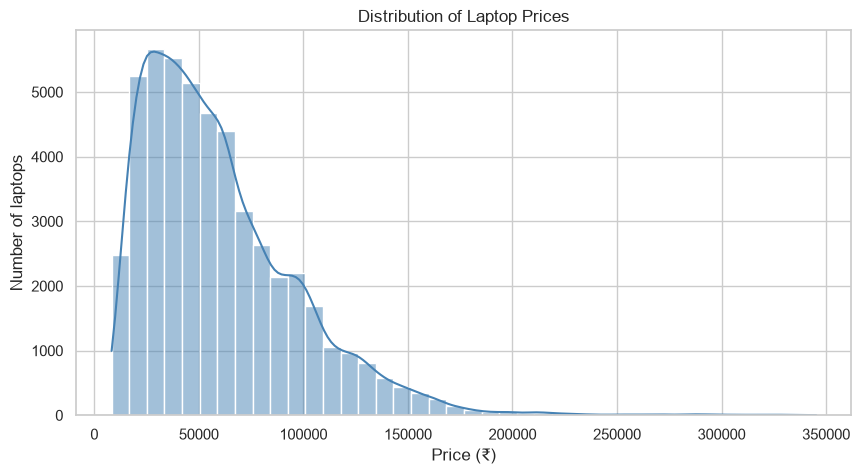

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Price"], bins=40, kde=True, color="steelblue")
plt.title("Distribution of Laptop Prices")
plt.xlabel("Price (₹)")
plt.ylabel("Number of laptops")
plt.show()

Most laptops are cheap and a few are very expensive, so the graph leans to the **right** (skewed).

### 3.2 Distribution of log(Price)
Taking the logarithm makes the shape more balanced. This is why we train the model on `log(Price)`.

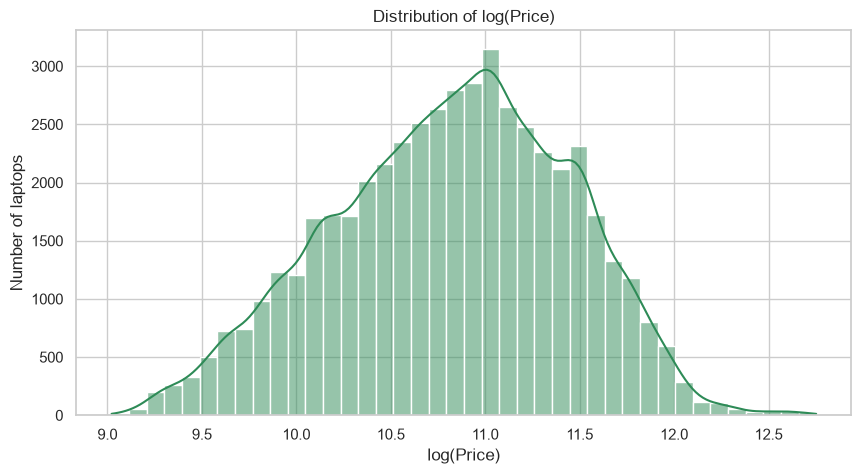

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(np.log(df["Price"]), bins=40, kde=True, color="seagreen")
plt.title("Distribution of log(Price)")
plt.xlabel("log(Price)")
plt.ylabel("Number of laptops")
plt.show()

## 4. Company (Brand)
### 4.1 How many laptops does each company have?

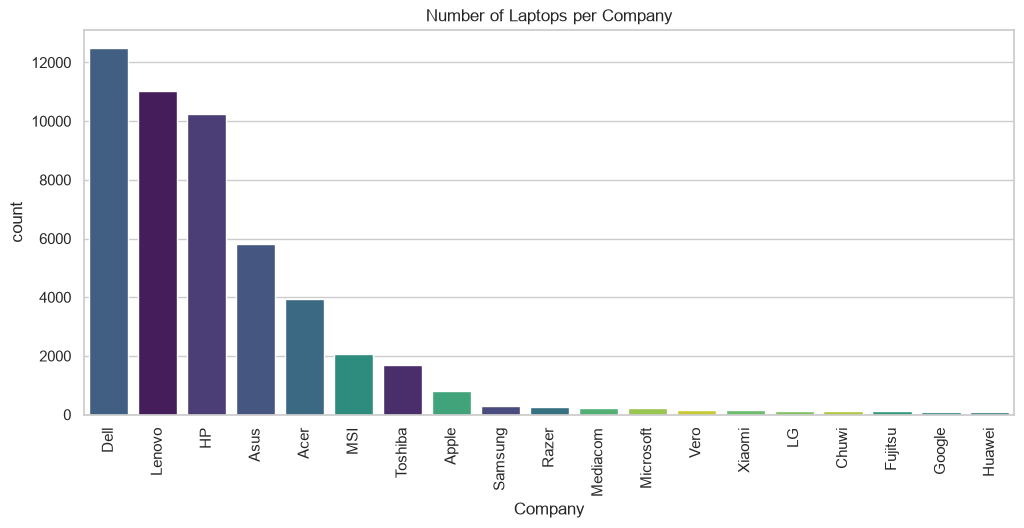

In [6]:
plt.figure(figsize=(12, 5))
order = df["Company"].value_counts().index
sns.countplot(data=df, x="Company", order=order, hue="Company", palette="viridis", legend=False)
plt.xticks(rotation=90)
plt.title("Number of Laptops per Company")
plt.show()

### 4.2 Average price of each company

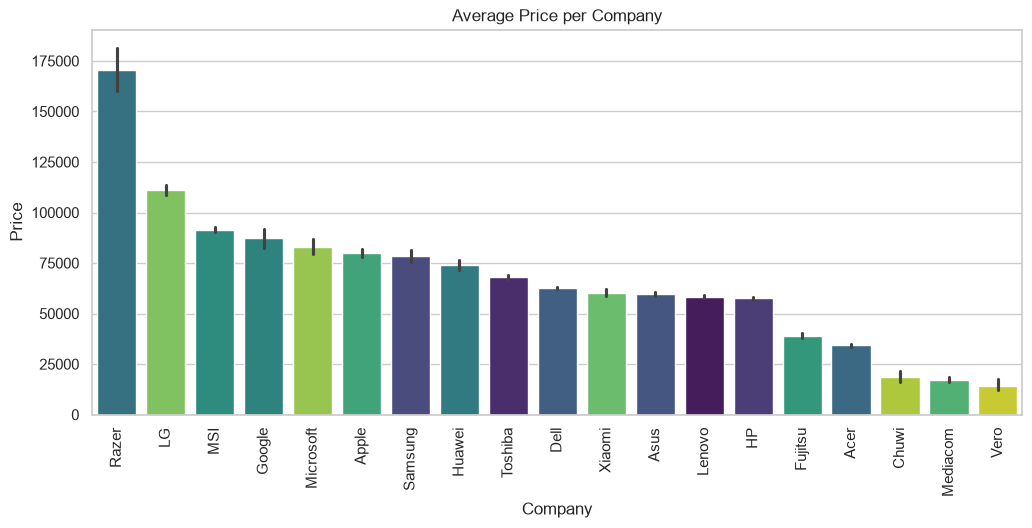

In [7]:
plt.figure(figsize=(12, 5))
order = df.groupby("Company")["Price"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="Company", y="Price", order=order, hue="Company", palette="viridis", legend=False)
plt.xticks(rotation=90)
plt.title("Average Price per Company")
plt.show()

## 5. Laptop Type
### 5.1 Count of each type

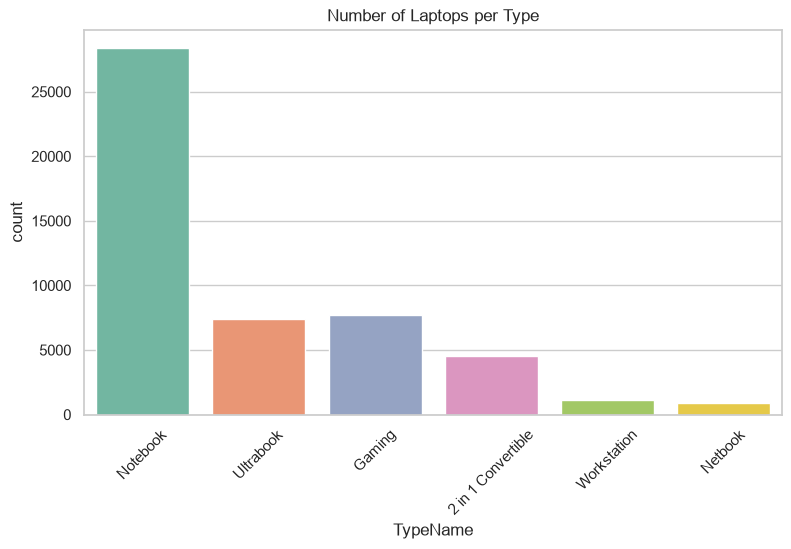

In [8]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="TypeName", hue="TypeName", palette="Set2", legend=False)
plt.xticks(rotation=45)
plt.title("Number of Laptops per Type")
plt.show()

### 5.2 Average price of each type

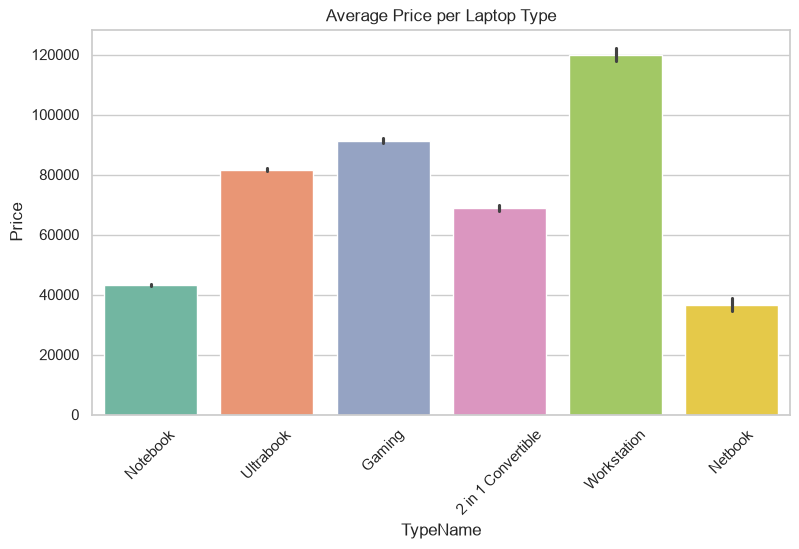

In [9]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="TypeName", y="Price", hue="TypeName", palette="Set2", legend=False)
plt.xticks(rotation=45)
plt.title("Average Price per Laptop Type")
plt.show()

## 6. RAM

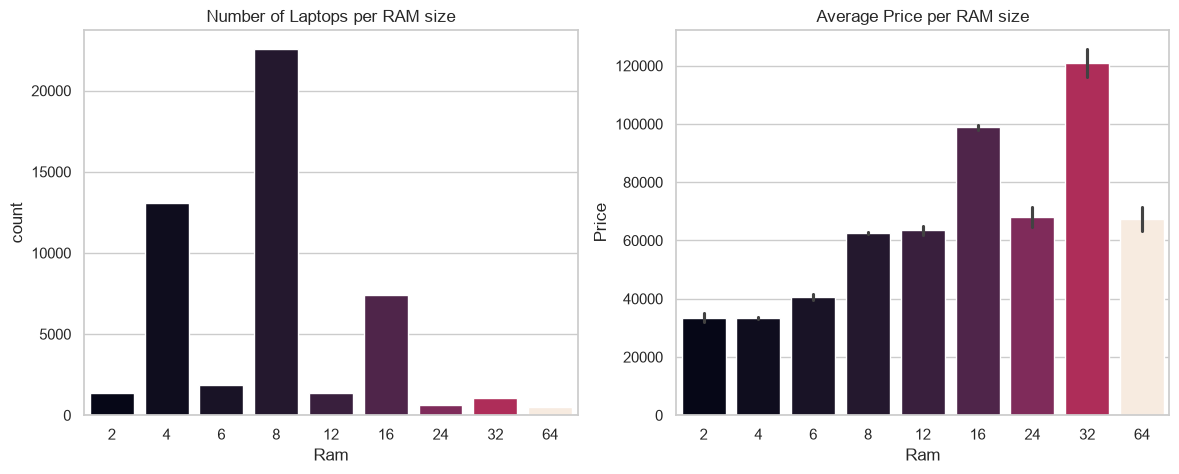

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="Ram", hue="Ram", palette="rocket", legend=False, ax=ax[0])
ax[0].set_title("Number of Laptops per RAM size")

sns.barplot(data=df, x="Ram", y="Price", hue="Ram", palette="rocket", legend=False, ax=ax[1])
ax[1].set_title("Average Price per RAM size")

plt.show()

Price generally rises with RAM (a few sizes such as 24 GB and 64 GB break the pattern). RAM is still one of the strongest price factors.

## 7. Screen Features
### 7.1 Touchscreen

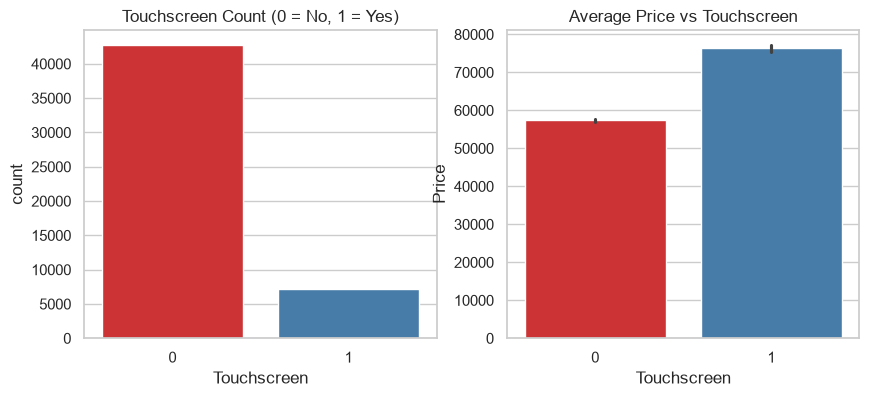

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=df, x="Touchscreen", hue="Touchscreen", palette="Set1", legend=False, ax=ax[0])
ax[0].set_title("Touchscreen Count (0 = No, 1 = Yes)")

sns.barplot(data=df, x="Touchscreen", y="Price", hue="Touchscreen", palette="Set1", legend=False, ax=ax[1])
ax[1].set_title("Average Price vs Touchscreen")

plt.show()

### 7.2 IPS Display

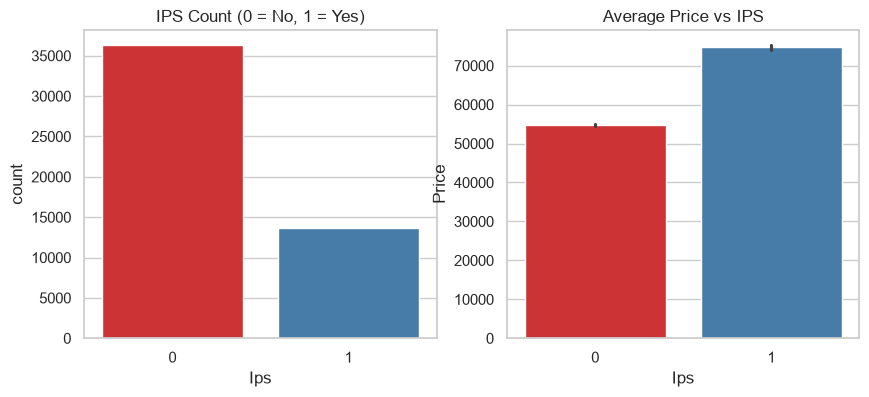

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=df, x="Ips", hue="Ips", palette="Set1", legend=False, ax=ax[0])
ax[0].set_title("IPS Count (0 = No, 1 = Yes)")

sns.barplot(data=df, x="Ips", y="Price", hue="Ips", palette="Set1", legend=False, ax=ax[1])
ax[1].set_title("Average Price vs IPS")

plt.show()

### 7.3 PPI (screen sharpness) vs Price
We plot only 2,000 random laptops so the chart stays clear.

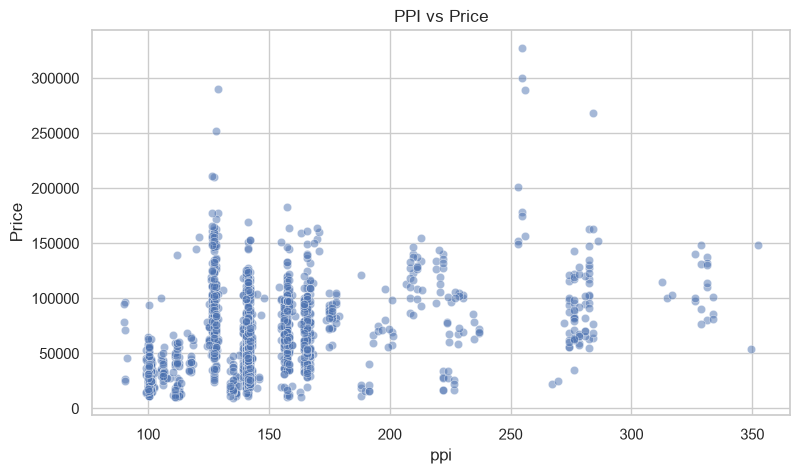

In [13]:
sample = df.sample(2000, random_state=1)

plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample, x="ppi", y="Price", alpha=0.5)
plt.title("PPI vs Price")
plt.show()

## 8. CPU Brand

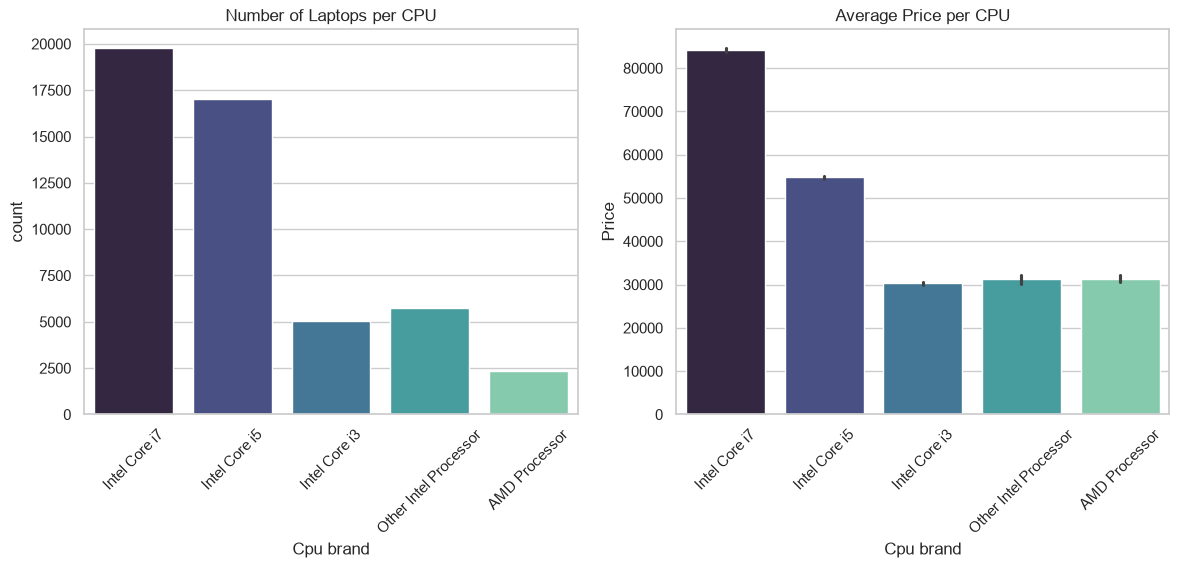

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="Cpu brand", hue="Cpu brand", palette="mako", legend=False, ax=ax[0])
ax[0].set_title("Number of Laptops per CPU")
ax[0].tick_params(axis="x", rotation=45)

sns.barplot(data=df, x="Cpu brand", y="Price", hue="Cpu brand", palette="mako", legend=False, ax=ax[1])
ax[1].set_title("Average Price per CPU")
ax[1].tick_params(axis="x", rotation=45)

plt.show()

## 9. GPU Brand

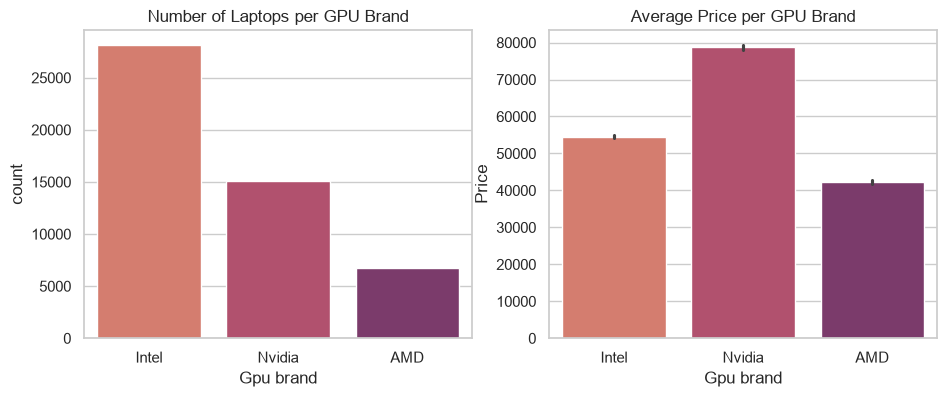

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x="Gpu brand", hue="Gpu brand", palette="flare", legend=False, ax=ax[0])
ax[0].set_title("Number of Laptops per GPU Brand")

sns.barplot(data=df, x="Gpu brand", y="Price", hue="Gpu brand", palette="flare", legend=False, ax=ax[1])
ax[1].set_title("Average Price per GPU Brand")

plt.show()

## 10. Operating System

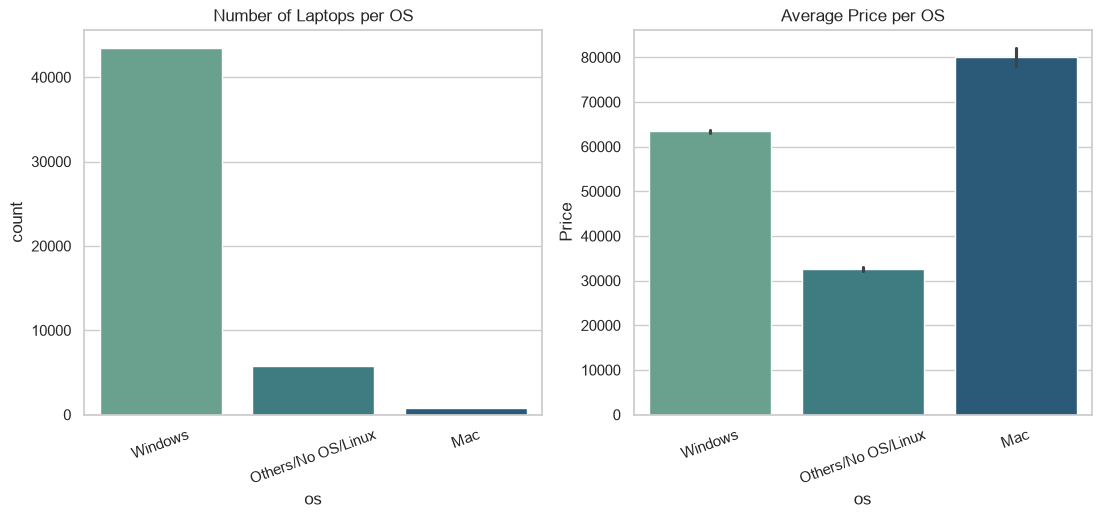

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x="os", hue="os", palette="crest", legend=False, ax=ax[0])
ax[0].set_title("Number of Laptops per OS")
ax[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="os", y="Price", hue="os", palette="crest", legend=False, ax=ax[1])
ax[1].set_title("Average Price per OS")
ax[1].tick_params(axis="x", rotation=20)

plt.show()

## 11. Storage (SSD and HDD)

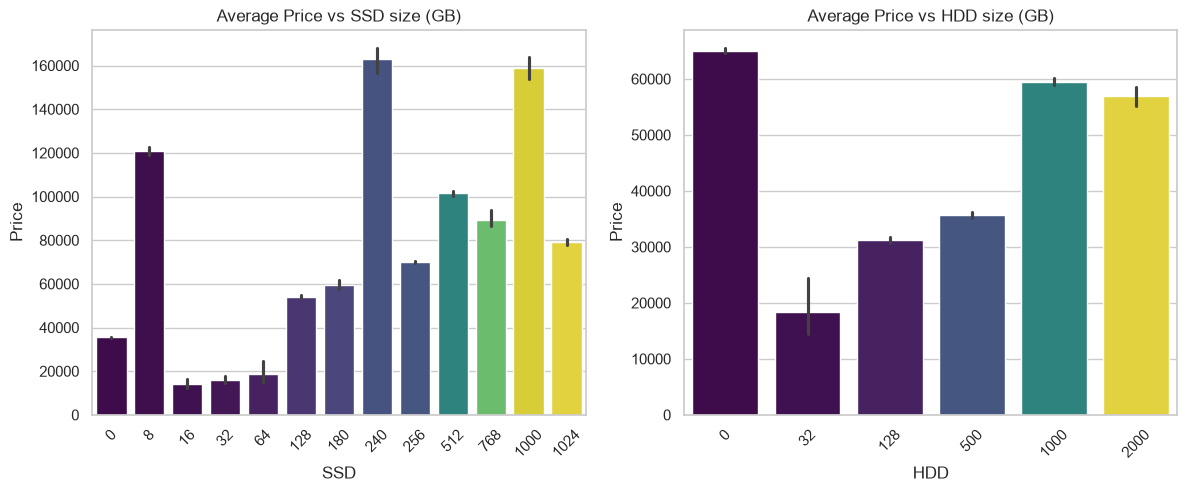

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x="SSD", y="Price", hue="SSD", palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Average Price vs SSD size (GB)")
ax[0].tick_params(axis="x", rotation=45)

sns.barplot(data=df, x="HDD", y="Price", hue="HDD", palette="viridis", legend=False, ax=ax[1])
ax[1].set_title("Average Price vs HDD size (GB)")
ax[1].tick_params(axis="x", rotation=45)

plt.show()

A bigger SSD clearly raises the price, while HDD size has little (even slightly negative) effect on price.

## 12. Weight vs Price

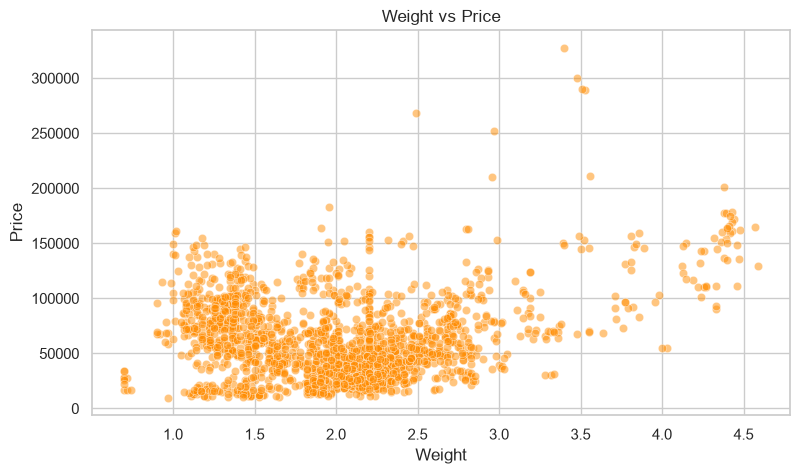

In [18]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample, x="Weight", y="Price", alpha=0.5, color="darkorange")
plt.title("Weight vs Price")
plt.show()

## 13. Correlation Heatmap
Correlation shows how strongly two **number** columns move together  
(+1 = move together, 0 = no link, -1 = move opposite).

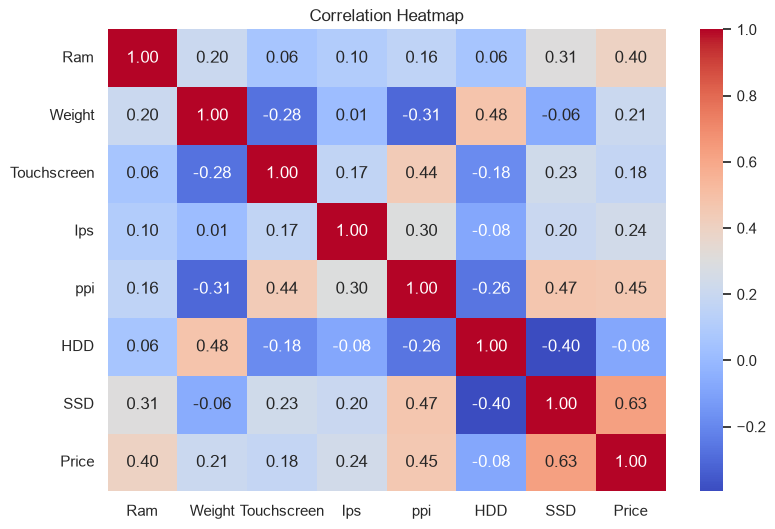

In [19]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [20]:
# correlation of every column with Price
df.corr(numeric_only=True)["Price"].sort_values(ascending=False)

Price          1.000000
SSD            0.628448
ppi            0.454719
Ram            0.398115
Ips            0.237914
Weight         0.205246
Touchscreen    0.177723
HDD           -0.082423
Name: Price, dtype: float64

## 14. Summary of Findings
* **SSD, PPI and RAM** have the strongest link with price (see the correlation table above).
* **Razer, LG and MSI** are the most expensive brands, **Workstation** and **Gaming** the most expensive types.
* **IPS** and **Touchscreen** laptops cost more.
* **Intel Core i7** laptops cost more than i5 / i3 / AMD.
* **Mac** laptops cost more than Windows laptops, and **Nvidia** GPU laptops cost more than Intel / AMD.

Next → open **`03_ML_Model.ipynb`** to train the models.